# Week 7 — Neural Time Series: From Voltage Traces to Oscillations and Synchrony

**Signal processing for electrophysiology-style data**

Neural recordings are often time series rather than one value per cell or trial. EEG, LFP, ECoG, calcium traces, and many behavioral signals are sampled repeatedly through time.

The scientific questions for this notebook are:

> **Does stimulation change theta-band activity in hippocampus?**

and

> **Does stimulation change theta-band synchrony between hippocampus and prefrontal cortex?**

The dataset is synthetic but structured like a repeated-trial electrophysiology experiment:

- 12 animals;
- 8 trials per animal;
- 5 seconds per trial;
- two simultaneously recorded signals;
- a sampling rate of 200 Hz.

## Learning goals

By the end of class you should be able to:

1. identify sampling rate, sampling interval, and Nyquist frequency;
2. distinguish time-domain and frequency-domain views of the same signal;
3. estimate a power spectral density using Welch's method;
4. compute band-limited power;
5. explain why trial averaging can hide oscillatory activity;
6. estimate frequency-specific synchrony using coherence;


In [1]:
from io import BytesIO
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal, stats

pd.set_option('display.max_columns', 30)

GITHUB_RAW = (
    'https://raw.githubusercontent.com/'
    'willi3by/Survey_of_Methods_in_Comp_Neuro_Fall_2026/'
    'main/Data/Week_07'
)

def github_csv(filename):
    url = f"{GITHUB_RAW}/{filename}"
    req = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    try:
        with urlopen(req) as response:
            return pd.read_csv(BytesIO(response.read()))
    except HTTPError as e:
        raise RuntimeError(
            f"GitHub returned HTTP {e.code} for {url}. "
            "Check that the file exists in Data/Week_07 on the main branch."
        ) from e
    except URLError as e:
        raise RuntimeError(
            f"Could not reach GitHub while loading {url}. "
            "Check the notebook's internet connection."
        ) from e

lfp = github_csv('lfp_trials.csv')
animals = github_csv('animal_metadata.csv')

data = lfp.merge(animals, on='animal_id', validate='many_to_one')

FS = int(animals['sampling_rate_hz'].iloc[0])

print(f"{data['animal_id'].nunique()} animals")
print(f"{data.groupby('animal_id')['trial_id'].nunique().iloc[0]} trials per animal")
print(f"Sampling rate: {FS} Hz")
data.head()


12 animals
8 trials per animal
Sampling rate: 200 Hz


,animal_id,trial_id,time_s,hippocampus_uV,pfc_uV,treatment,treatment_binary,sampling_rate_hz
0,A01,1,0.000,2.775689,1.148697,Control,0,200
1,A01,1,0.005,1.117892,8.296476,Control,0,200
2,A01,1,0.010,1.214819,1.726382,Control,0,200
3,A01,1,0.015,-1.645706,-1.207313,Control,0,200
4,A01,1,0.020,-4.347355,2.087095,Control,0,200


## 1. Sampling turns a continuous signal into numbers

A neural voltage changes continuously in time, but a digital recording stores measurements at discrete time points.

If the sampling rate is \(f_s\) samples per second, the sampling interval is

$$
\Delta t = \frac{1}{f_s}.
$$

For a sampling rate of 200 Hz:

- 200 voltage measurements are stored each second;
- samples are separated by 0.005 seconds;
- the highest frequency that can be represented without aliasing is the **Nyquist frequency**:

$$
f_{\mathrm{Nyquist}} = \frac{f_s}{2}.
$$

Frequencies above the Nyquist limit can appear as false lower-frequency signals if they enter the sampled data.


In [2]:
dt = 1 / FS
nyquist = FS / 2

print(f"Sampling interval: {dt:.4f} s")
print(f"Nyquist frequency: {nyquist:.1f} Hz")


Sampling interval: 0.0050 s
Nyquist frequency: 100.0 Hz


## 2. Start in the time domain

A time-domain plot shows signal amplitude as a function of time.

Before calculating any summary statistic, inspect the recording.

Look for:

- oscillations;
- slow drift;
- transient events;
- clipping;
- unusually large artifacts;
- differences between channels.


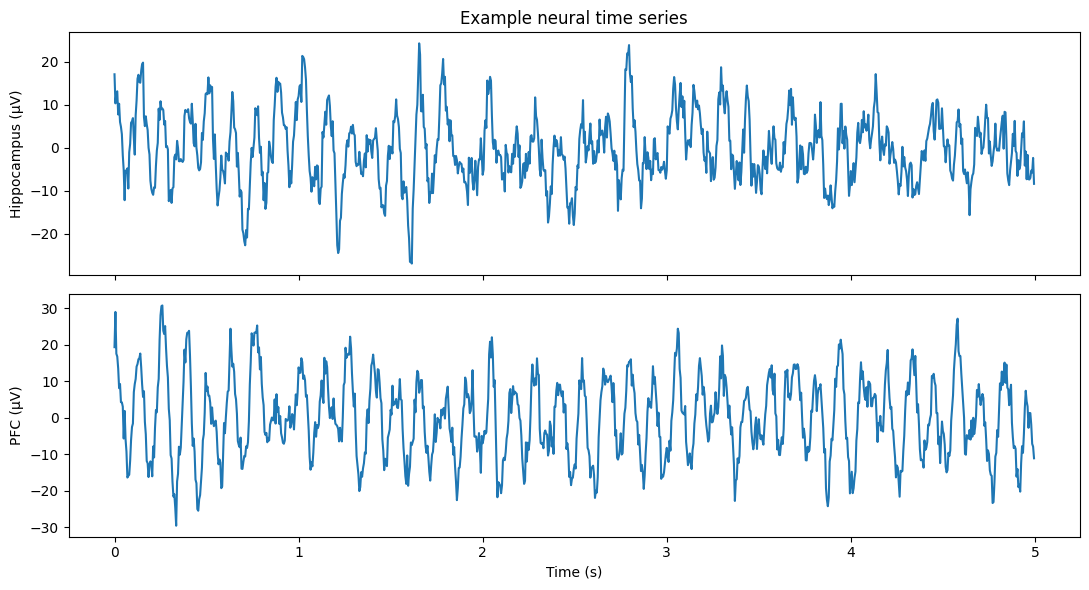

In [3]:
example = data[
    (data['animal_id'] == 'A08') &
    (data['trial_id'] == 1)
].copy()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

axes[0].plot(example['time_s'], example['hippocampus_uV'])
axes[0].set_ylabel('Hippocampus (µV)')
axes[0].set_title('Example neural time series')

axes[1].plot(example['time_s'], example['pfc_uV'])
axes[1].set_ylabel('PFC (µV)')
axes[1].set_xlabel('Time (s)')

plt.tight_layout()
plt.show()


### Interpretation prompt

From the raw trace alone:

1. Can you confidently identify the dominant oscillation frequency?
2. Are the hippocampal and PFC signals perfectly synchronized?
3. Would one 5-second trace be enough to conclude that a treatment changes oscillatory activity?

A time-domain plot is essential for quality control, but some questions are easier to answer after representing the signal by frequency.


## 3. The same signal can be represented by frequency

A complicated neural trace can contain multiple oscillatory components.

Conceptually, Fourier analysis asks:

> How much of the signal can be described by oscillations at different frequencies?

A pure sinusoid can be written as

$$
x(t) = A \sin(2\pi f t + \phi),
$$

where:

- \(A\) is amplitude;
- \(f\) is frequency in Hz;
- \(\phi\) is phase.

Real neural recordings contain many frequencies simultaneously, plus noise and transient events.

For noisy biological data, a common approach is **Welch's power spectral density estimate**. Welch's method:

1. divides the signal into overlapping windows;
2. estimates a spectrum in each window;
3. averages the spectra.

This reduces the variability of a single raw periodogram.


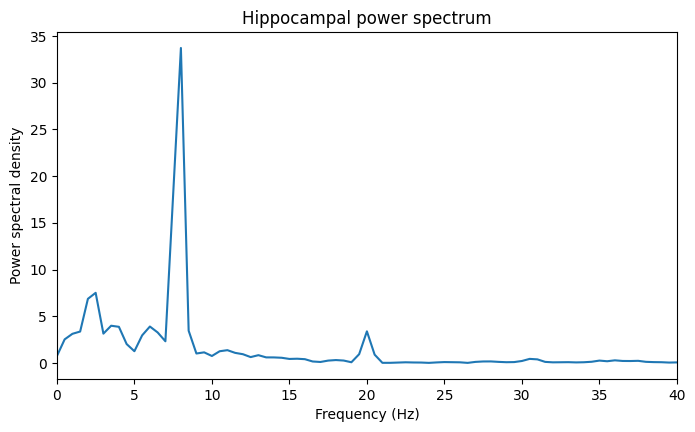

In [5]:
freq, psd = signal.welch(
    example['hippocampus_uV'].to_numpy(),
    fs=FS,
    nperseg=400,
    noverlap=200
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(freq, psd)
ax.set_xlim(0, 40)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power spectral density')
ax.set_title('Hippocampal power spectrum')
plt.show()

### Reading a power spectrum

A peak means that the signal contains relatively strong variation at that frequency.

For this exercise, define the **theta band** as 6–10 Hz.

A spectral peak around 8 Hz means that the voltage trace contains a strong oscillatory component with approximately eight cycles per second.

It does **not** by itself establish:

- the biological source of that rhythm;
- that every trial contains the same oscillation;
- that the oscillation is stationary for the entire recording;
- that the rhythm is caused by the experimental manipulation.


## 4. Trial averaging can hide an oscillation

Suppose every trial contains an 8-Hz rhythm, but the rhythm begins with a different phase on each trial.

If we average the voltage traces point-by-point, positive and negative phases can cancel.

This produces an important distinction:

- **evoked activity** is phase-locked to the event and survives trial averaging;
- **induced activity** can change in power without being phase-locked and may disappear in the average waveform.

Compare the mean waveform with the mean power spectrum.


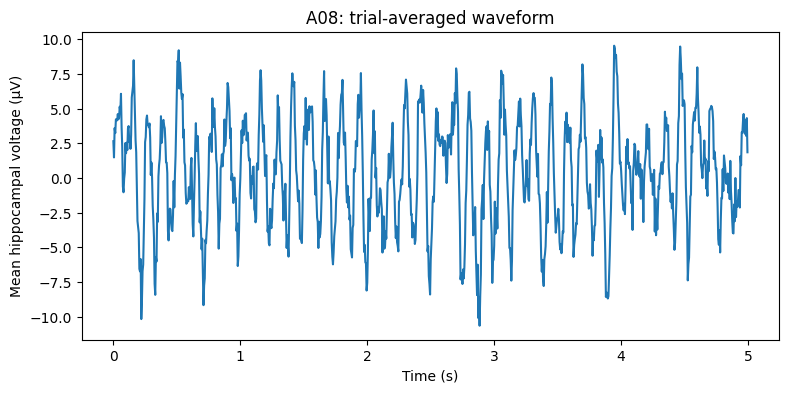

In [6]:
animal_id = 'A08'
hpc = data[data['animal_id'] == animal_id].pivot(
    index='time_s',
    columns='trial_id',
    values='hippocampus_uV'
)

mean_trace = hpc.mean(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hpc.index, mean_trace)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Mean hippocampal voltage (µV)')
ax.set_title(f'{animal_id}: trial-averaged waveform')
plt.show()


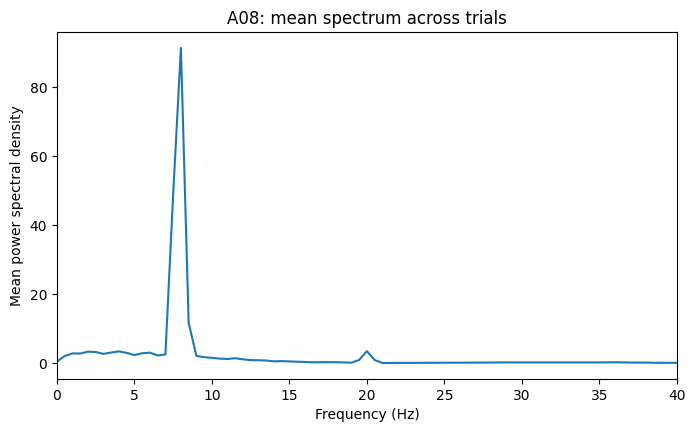

In [8]:
trial_psds = []

for trial_id, trial in data[data['animal_id'] == animal_id].groupby('trial_id'):
    f, p = signal.welch(
        trial['hippocampus_uV'].to_numpy(),
        fs=FS,
        nperseg=400,
        noverlap=200
    )
    trial_psds.append(p)

mean_psd = np.mean(trial_psds, axis=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f, mean_psd)
ax.set_xlim(0, 40)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Mean power spectral density')
ax.set_title(f'{animal_id}: mean spectrum across trials')
plt.show()

### Interpretation prompt

If the time-domain average looks small but the power spectrum has a clear theta peak, what happened?

The oscillation was present across trials, but its **phase varied**. Averaging voltage removed much of the oscillatory waveform, while averaging power preserved the amount of rhythmic activity.

The correct representation depends on the scientific question.


## 5. Reduce a spectrum to band power

Sometimes the scientific question concerns a predefined frequency band rather than the complete spectrum.

Theta-band power can be estimated by integrating the power spectral density between 6 and 10 Hz:

$$
P_{\theta}
=
\int_{6}^{10} PSD(f)\,df.
$$

We will compute theta power separately for every trial.

The repeated trials are useful measurements, but treatment was assigned to animals. Therefore, treatment comparisons should ultimately be summarized at the animal level.


In [9]:
def band_power(x, fs, low, high):
    f, pxx = signal.welch(
        x,
        fs=fs,
        nperseg=400,
        noverlap=200
    )
    keep = (f >= low) & (f <= high)
    return np.trapezoid(pxx[keep], f[keep])

trial_rows = []

for (animal_id, trial_id), trial in data.groupby(['animal_id', 'trial_id']):
    trial_rows.append({
        'animal_id': animal_id,
        'trial_id': trial_id,
        'theta_power_hpc': band_power(
            trial['hippocampus_uV'].to_numpy(),
            FS, 6, 10
        ),
        'theta_power_pfc': band_power(
            trial['pfc_uV'].to_numpy(),
            FS, 6, 10
        )
    })

trial_features = pd.DataFrame(trial_rows).merge(
    animals[['animal_id', 'treatment']],
    on='animal_id'
)

trial_features.head()


,animal_id,trial_id,theta_power_hpc,theta_power_pfc,treatment
0,A01,1,22.331082,11.537705,Control
1,A01,2,17.377989,14.309986,Control
2,A01,3,36.792291,13.888840,Control
3,A01,4,40.042547,18.162360,Control
4,A01,5,60.551893,16.784994,Control


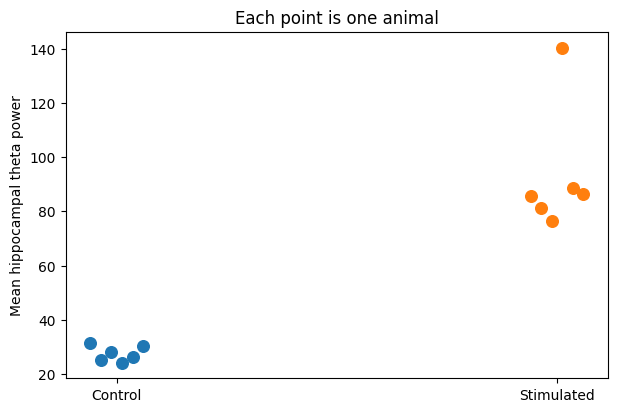

In [10]:
animal_power = (
    trial_features
    .groupby(['animal_id', 'treatment'])[
        ['theta_power_hpc', 'theta_power_pfc']
    ]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7, 4.5))

for treatment, group in animal_power.groupby('treatment'):
    x = 0 if treatment == 'Control' else 1
    jitter = np.linspace(-0.06, 0.06, len(group))
    ax.scatter(
        np.full(len(group), x) + jitter,
        group['theta_power_hpc'],
        s=70,
        label=treatment
    )

ax.set_xticks([0, 1], ['Control', 'Stimulated'])
ax.set_ylabel('Mean hippocampal theta power')
ax.set_title('Each point is one animal')
plt.show()


In [11]:
control = animal_power.loc[
    animal_power['treatment'] == 'Control',
    'theta_power_hpc'
]

stimulated = animal_power.loc[
    animal_power['treatment'] == 'Stimulated',
    'theta_power_hpc'
]

test = stats.ttest_ind(
    control,
    stimulated,
    equal_var=False
)

print(f"Control mean: {control.mean():.2f}")
print(f"Stimulated mean: {stimulated.mean():.2f}")
print(f"Welch t-test p-value: {test.pvalue:.4f}")


Control mean: 27.47
Stimulated mean: 93.18
Welch t-test p-value: 0.0010


## 6. Power and synchrony are different questions

Two brain regions can both show strong theta power without their theta rhythms being synchronized.

To quantify frequency-specific similarity between two signals, one option is **magnitude-squared coherence**.

Coherence at frequency $f$ is

$$
C_{xy}(f)
=
\frac{|S_{xy}(f)|^2}
{S_{xx}(f)S_{yy}(f)},
$$

where:

- $S_{xx}(f)$ is the power spectrum of signal $x$;
- $S_{yy}(f)$ is the power spectrum of signal $y$;
- $S_{xy}(f)$ is their cross-spectrum.

Coherence ranges from 0 to 1:

- near 0: little consistent frequency-specific relationship;
- near 1: strong consistent relationship at that frequency.

High coherence does not prove direct anatomical connectivity or causal influence.

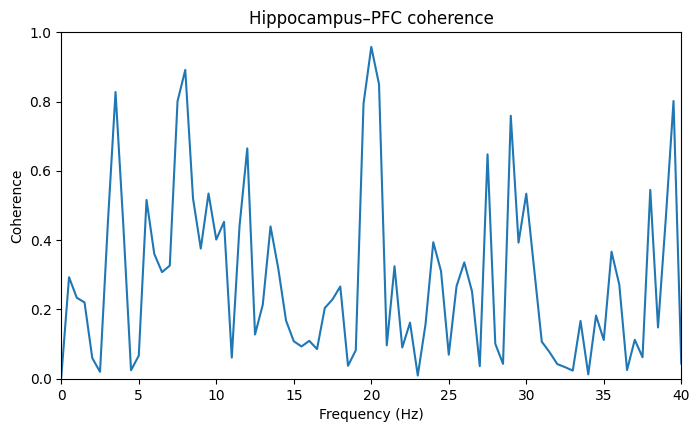

In [14]:
f_coh, coh = signal.coherence(
    example['hippocampus_uV'].to_numpy(),
    example['pfc_uV'].to_numpy(),
    fs=FS,
    nperseg=400,
    noverlap=200
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f_coh, coh)
ax.set_xlim(0, 40)
ax.set_ylim(0, 1)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Coherence')
ax.set_title('Hippocampus–PFC coherence')
plt.show()


### Interpretation prompt

Imagine both regions show a strong 8-Hz power peak.

Does that guarantee high 8-Hz coherence?

No. Each region can oscillate strongly at the same frequency while their phases vary independently.

Power asks:

> **How much activity occurs at this frequency?**

Coherence asks:

> **How consistently are the two signals related at this frequency?**


In [15]:
def theta_coherence(x, y, fs):
    f, cxy = signal.coherence(
        x,
        y,
        fs=fs,
        nperseg=400,
        noverlap=200
    )
    keep = (f >= 6) & (f <= 10)
    return cxy[keep].mean()

coherence_rows = []

for (animal_id, trial_id), trial in data.groupby(['animal_id', 'trial_id']):
    coherence_rows.append({
        'animal_id': animal_id,
        'trial_id': trial_id,
        'theta_coherence': theta_coherence(
            trial['hippocampus_uV'].to_numpy(),
            trial['pfc_uV'].to_numpy(),
            FS
        )
    })

trial_coherence = pd.DataFrame(coherence_rows).merge(
    animals[['animal_id', 'treatment']],
    on='animal_id'
)

animal_coherence = (
    trial_coherence
    .groupby(['animal_id', 'treatment'])['theta_coherence']
    .mean()
    .reset_index()
)

animal_coherence


,animal_id,treatment,theta_coherence
0,A01,Control,0.336245
1,A02,Control,0.426705
2,A03,Control,0.400285
3,A04,Control,0.367801
4,A05,Control,0.406682
5,A06,Control,0.379998
6,A07,Stimulated,0.471556
7,A08,Stimulated,0.475615
8,A09,Stimulated,0.475562
9,A10,Stimulated,0.452159


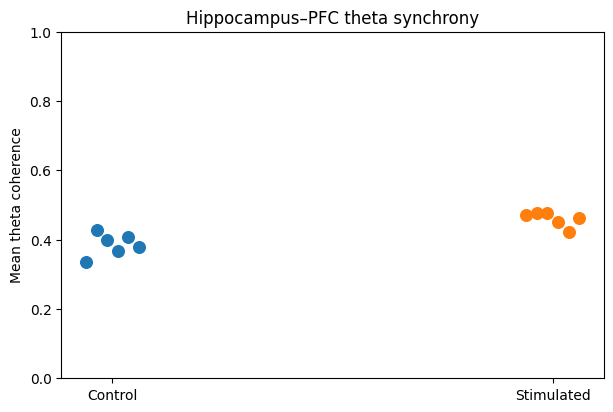

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for treatment, group in animal_coherence.groupby('treatment'):
    x = 0 if treatment == 'Control' else 1
    jitter = np.linspace(-0.06, 0.06, len(group))
    ax.scatter(
        np.full(len(group), x) + jitter,
        group['theta_coherence'],
        s=70
    )

ax.set_xticks([0, 1], ['Control', 'Stimulated'])
ax.set_ylim(0, 1)
ax.set_ylabel('Mean theta coherence')
ax.set_title('Hippocampus–PFC theta synchrony')
plt.show()


In [17]:
control_coherence = animal_coherence.loc[
    animal_coherence['treatment'] == 'Control',
    'theta_coherence'
]

stimulated_coherence = animal_coherence.loc[
    animal_coherence['treatment'] == 'Stimulated',
    'theta_coherence'
]

coherence_test = stats.ttest_ind(
    control_coherence,
    stimulated_coherence,
    equal_var=False
)

print(f"Control mean coherence: {control_coherence.mean():.3f}")
print(f"Stimulated mean coherence: {stimulated_coherence.mean():.3f}")
print(f"Welch t-test p-value: {coherence_test.pvalue:.4f}")


Control mean coherence: 0.386
Stimulated mean coherence: 0.460
Welch t-test p-value: 0.0012


## 7. Filtering: useful, but not neutral

A band-pass filter can isolate activity in a frequency range.

Here we isolate 6–10 Hz theta activity with a Butterworth filter.

A filter changes the data. Important choices include:

- passband;
- filter order;
- causal versus zero-phase filtering;
- treatment of signal edges;
- whether the sampling rate is adequate.

`filtfilt` applies the filter forward and backward. This avoids a phase shift, but it is **non-causal** and uses information from both directions in time.


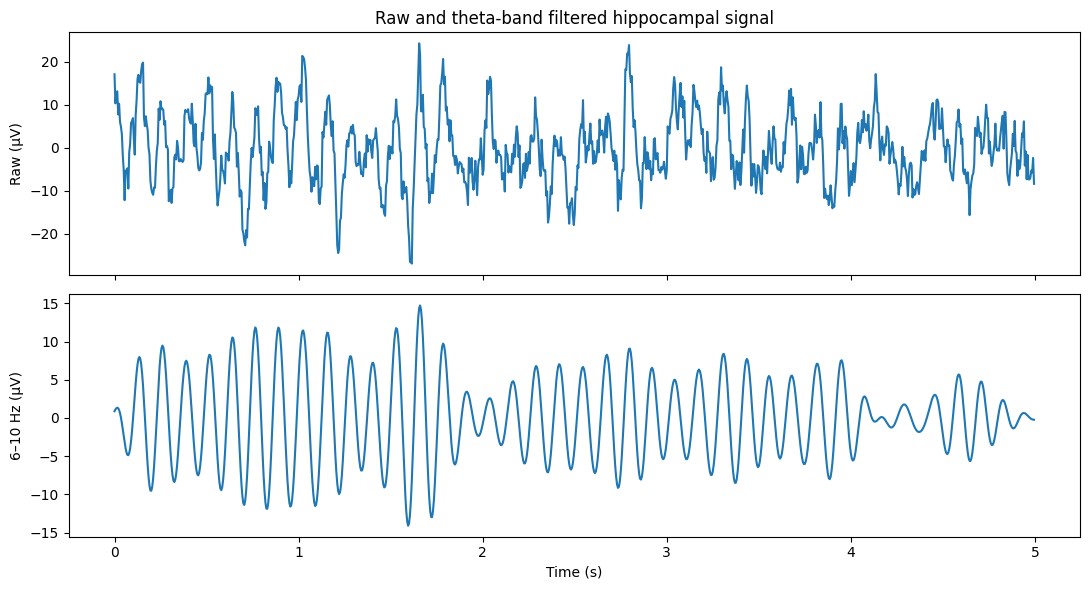

In [18]:
low = 6
high = 10

b, a = signal.butter(
    4,
    [low, high],
    btype='bandpass',
    fs=FS
)

theta_filtered = signal.filtfilt(
    b,
    a,
    example['hippocampus_uV']
)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

axes[0].plot(example['time_s'], example['hippocampus_uV'])
axes[0].set_ylabel('Raw (µV)')
axes[0].set_title('Raw and theta-band filtered hippocampal signal')

axes[1].plot(example['time_s'], theta_filtered)
axes[1].set_ylabel('6–10 Hz (µV)')
axes[1].set_xlabel('Time (s)')

plt.tight_layout()
plt.show()


## 8. Inspect artifacts before trusting spectra

Spectral analysis can transform a brief artifact into power across many frequencies.

Inspect this trial:


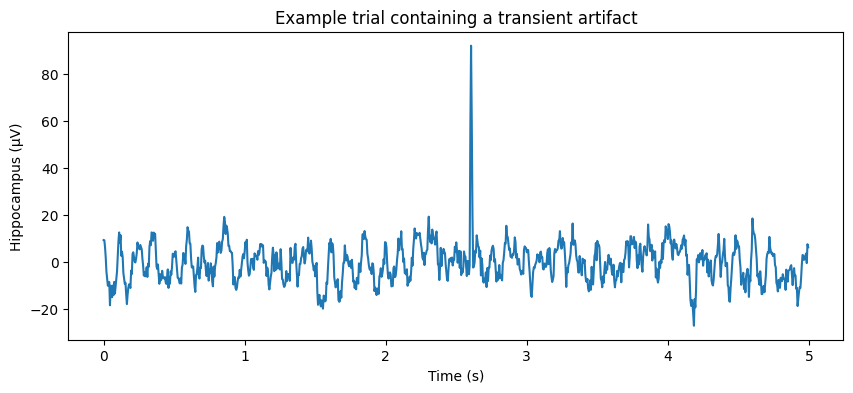

In [19]:
artifact_trial = data[
    (data['animal_id'] == 'A03') &
    (data['trial_id'] == 4)
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    artifact_trial['time_s'],
    artifact_trial['hippocampus_uV']
)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Hippocampus (µV)')
ax.set_title('Example trial containing a transient artifact')
plt.show()


A short transient can contribute broadband spectral energy.

This is why a good analysis does not begin with a power spectrum and ignore the raw data.

Possible responses to artifacts include:

- rejecting contaminated trials using predefined criteria;
- repairing known technical artifacts when justified;
- using robust analysis methods;
- reporting how quality-control decisions were made.

The correct approach depends on the recording modality and the source of the artifact.


## 9. Common failures

### Aliasing

Sampling too slowly can make high-frequency activity appear at the wrong frequency.

### Treating a spectral peak as proof of an oscillatory mechanism

A peak is a feature of the recorded signal. Its biological source requires additional evidence.

### Ignoring nonstationarity

A five-second spectrum summarizes the entire interval. A rhythm that appears only briefly may require a time-frequency analysis.

### Averaging voltage when the question concerns power

Variable phase can make a real oscillation disappear from the average waveform.

### Ignoring biological replication

Repeated time points and repeated trials do not create new independently treated animals.

### Over-interpreting coherence

Coherence measures statistical dependence at a frequency. It does not establish directionality, direct connectivity, or causality.

### Filtering without documenting choices

Filter settings can materially change the signal and must be treated as part of the analysis.
